# Gaussian Process reconstruction of Andrei’s final F1 scene

This GP-only notebook uses `final_race_track_map.py`, the synchronised car-position CSV, the track overlay, and `final_extract_sound_venues.py`. The source provides **721 frames at 0.25 s spacing**, covering **0–180 s**. Moving cars generate a synthetic free-field sound map. The 15 microphone configurations observe the same sequence. A fixed 15 m RBF GP and a phone-validated GP predict **2,132 spectator grid cells** independently at each frame.

All scores exclude microphone cells. Values are synthetic, unweighted broadband dB, not calibrated smartphone measurements or dBA.

## 1. Locate the project and confirm the sources

Run cells from top to bottom. Saved outputs load by default. Set `RUN_MODEL = True` to regenerate all 15 configurations, 30 GP prediction sequences, metrics, and figures.

In [1]:
from pathlib import Path
import csv
import hashlib
import sys
import numpy as np
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
ROOT = next((p for p in (current, *current.parents)
             if (p / '仿真/andreib/Working_final_maps/final_race_track_map.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the MDM3 project.')
sys.path.insert(0, str(ROOT / '仿真/austin'))
from gp_working_final_f1 import main, OUTPUT, INPUTS, PREDICTIONS, EVALUATION, TEAM_DIR

RUN_MODEL = False
if RUN_MODEL or not (EVALUATION / 'overall_metrics.csv').exists():
    main()

def read_csv(path):
    with path.open(newline='') as handle:
        return list(csv.DictReader(handle))

sources = read_csv(OUTPUT / 'source_files.csv')
for row in sources:
    current_hash = hashlib.sha256(Path(row['path']).read_bytes()).hexdigest()
    if current_hash != row['sha256']:
        raise ValueError(f"Source changed: {row['file']}. Set RUN_MODEL = True and rerun.")
    print(f"Verified: {row['path']} | SHA-256 {row['sha256'][:16]}...")
print('Output folder:', OUTPUT)

Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/final_race_track_map.py | SHA-256 b5472147bc3d4b8c...
Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/final_extract_sound_venues.py | SHA-256 ec8272c51dcae262...
Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/final_synchronised_f1.csv | SHA-256 3956a7e3dc49ca5b...
Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/final_f1_track_overlay.png | SHA-256 d0f7c7bb3e9eeb4f...
Output folder: /Users/a603/Desktop/MDM3/gp_final_f1_output


## 2. Model and evaluation settings

The baseline uses an RBF length scale of **15 m**. Phone CV tests **15, 30, 60, 100, 150, 250, and 400 m** using five held-out microphone folds. The larger candidates reflect the F1 scene’s kilometre-scale dimensions; no full-map truth is passed to model fitting or selection. Observation noise is assumed to be **0.5 dB**.

Both GPs receive the same 10, 30, 50, 100, or 250 microphones under random, grid, or clustered layouts (seed 42). Each prediction array has shape `(721, 2132)`. One length scale is selected per configuration using readings across the complete sequence: this is retrospective spatial reconstruction, not a test of future-time forecasting. Selections at the 400 m candidate boundary may warrant a wider search in a later experiment.

In [2]:
settings = read_csv(PREDICTIONS / 'model_settings.csv')[0]
for key, value in settings.items():
    print(f'{key}: {value}')
truth = np.load(EVALUATION / 'true_levels.npy', mmap_mode='r')
query = np.load(INPUTS / 'query_positions.npy', mmap_mode='r')
mask = np.load(INPUTS / 'allowed_mask.npy')
print('Truth:', truth.shape, '| audience queries:', query.shape, '| mask:', mask.shape)
example_eval = np.load(EVALUATION / 'evaluation_mask_100_grid.npy')
print('100-grid evaluation cells:', int(example_eval.sum()), '| excluded microphone cells:', int((~example_eval).sum()))
print('Prediction example:',
      np.load(PREDICTIONS / 'prediction_phone_cv_100_grid.npy', mmap_mode='r').shape)

kernel: RBF
fixed_length_scale_m: 15.0
cv_candidate_lengths_m: 15.0,30.0,60.0,100.0,150.0,250.0,400.0
signal_std_db: 15.0
assumed_noise_std_db: 0.5
jitter: 1e-06
frame_model: independent_spatial_GP
field: unweighted synthetic broadband SPL
evaluation_region: audience mask excluding microphone cells
display_frame: 80
display_time_seconds: 20.0
car_count: 17
cv_time_scope: all frames; retrospective spatial reconstruction
Truth: (721, 2132) | audience queries: (2132, 2) | mask: (85, 110)
100-grid evaluation cells: 2032 | excluded microphone cells: 100
Prediction example: (721, 2132)


## 3. Results for every configuration

**MAE** is mean absolute error, **RMSE** emphasizes larger errors, **bias** shows average over- or under-prediction, **P95** is the 95th percentile of absolute error, and **high-level MAE** is computed on the loudest 10% of unobserved audience cells in each frame. Every metric below combines **all 721 frames**, rather than just the displayed frame. The complete values are in `overall_metrics.csv`; `frame_metrics.csv` contains one row per model, layout, and frame.

In [3]:
rows = read_csv(EVALUATION / 'overall_metrics.csv')
lines = ['| Layout | Phones | GP | RMSE (dB) | MAE (dB) | High-level MAE (dB) |',
         '|:--|--:|:--|--:|--:|--:|']
for layout in ('random', 'grid', 'clustered'):
    for count in (10, 30, 50, 100, 250):
        for model in ('fixed_15m', 'phone_cv'):
            row = next(r for r in rows if r['layout'] == layout
                       and int(r['phone_count']) == count and r['model'] == model)
            lines.append(f"| {layout} | {count} | {model} | {float(row['RMSE_db']):.3f} | "
                         f"{float(row['MAE_db']):.3f} | "
                         f"{float(row['high_level_MAE_db']):.3f} |")
display(Markdown('\n'.join(lines)))

| Layout | Phones | GP | RMSE (dB) | MAE (dB) | High-level MAE (dB) |
|:--|--:|:--|--:|--:|--:|
| random | 10 | fixed_15m | 5.727 | 4.609 | 11.143 |
| random | 10 | phone_cv | 1.814 | 1.060 | 3.368 |
| random | 30 | fixed_15m | 5.381 | 4.330 | 10.456 |
| random | 30 | phone_cv | 0.956 | 0.550 | 1.518 |
| random | 50 | fixed_15m | 5.201 | 4.169 | 9.952 |
| random | 50 | phone_cv | 0.668 | 0.338 | 0.991 |
| random | 100 | fixed_15m | 4.786 | 3.782 | 9.069 |
| random | 100 | phone_cv | 0.349 | 0.156 | 0.462 |
| random | 250 | fixed_15m | 3.856 | 2.861 | 6.914 |
| random | 250 | phone_cv | 0.179 | 0.068 | 0.272 |
| grid | 10 | fixed_15m | 5.584 | 4.604 | 10.832 |
| grid | 10 | phone_cv | 1.668 | 0.984 | 2.977 |
| grid | 30 | fixed_15m | 5.333 | 4.321 | 10.455 |
| grid | 30 | phone_cv | 0.918 | 0.516 | 1.600 |
| grid | 50 | fixed_15m | 5.123 | 4.083 | 10.173 |
| grid | 50 | phone_cv | 0.486 | 0.245 | 0.807 |
| grid | 100 | fixed_15m | 4.634 | 3.667 | 8.977 |
| grid | 100 | phone_cv | 0.281 | 0.129 | 0.476 |
| grid | 250 | fixed_15m | 3.060 | 2.291 | 5.470 |
| grid | 250 | phone_cv | 0.114 | 0.043 | 0.176 |
| clustered | 10 | fixed_15m | 7.459 | 5.620 | 12.944 |
| clustered | 10 | phone_cv | 7.217 | 5.163 | 11.918 |
| clustered | 30 | fixed_15m | 7.554 | 5.689 | 12.993 |
| clustered | 30 | phone_cv | 7.618 | 5.299 | 11.578 |
| clustered | 50 | fixed_15m | 7.625 | 5.747 | 12.983 |
| clustered | 50 | phone_cv | 7.459 | 5.365 | 12.194 |
| clustered | 100 | fixed_15m | 7.681 | 5.809 | 12.797 |
| clustered | 100 | phone_cv | 7.459 | 5.349 | 11.925 |
| clustered | 250 | fixed_15m | 7.890 | 6.083 | 12.793 |
| clustered | 250 | phone_cv | 7.727 | 5.730 | 12.126 |

Compare phone-CV scores with full-spectator errors. Clustered phones mainly validate their own neighbourhood, so a small held-out-phone error can coexist with poor coverage elsewhere. The 15 m baseline is retained for continuity with the other scenes; it is short relative to this circuit.

## 4. All 15 microphone configurations

Neon-green, black-edged dots show the sampled positions over **frame 80 (20 s)**, matching Andrei’s default display frame. The field uses `inferno`; the original track, viewing-area overlay, and car markers come from Andrei’s drawing function. Locations stay fixed across all 721 frames. “Grid” means approximately even sampling constrained to the irregular spectator mask.

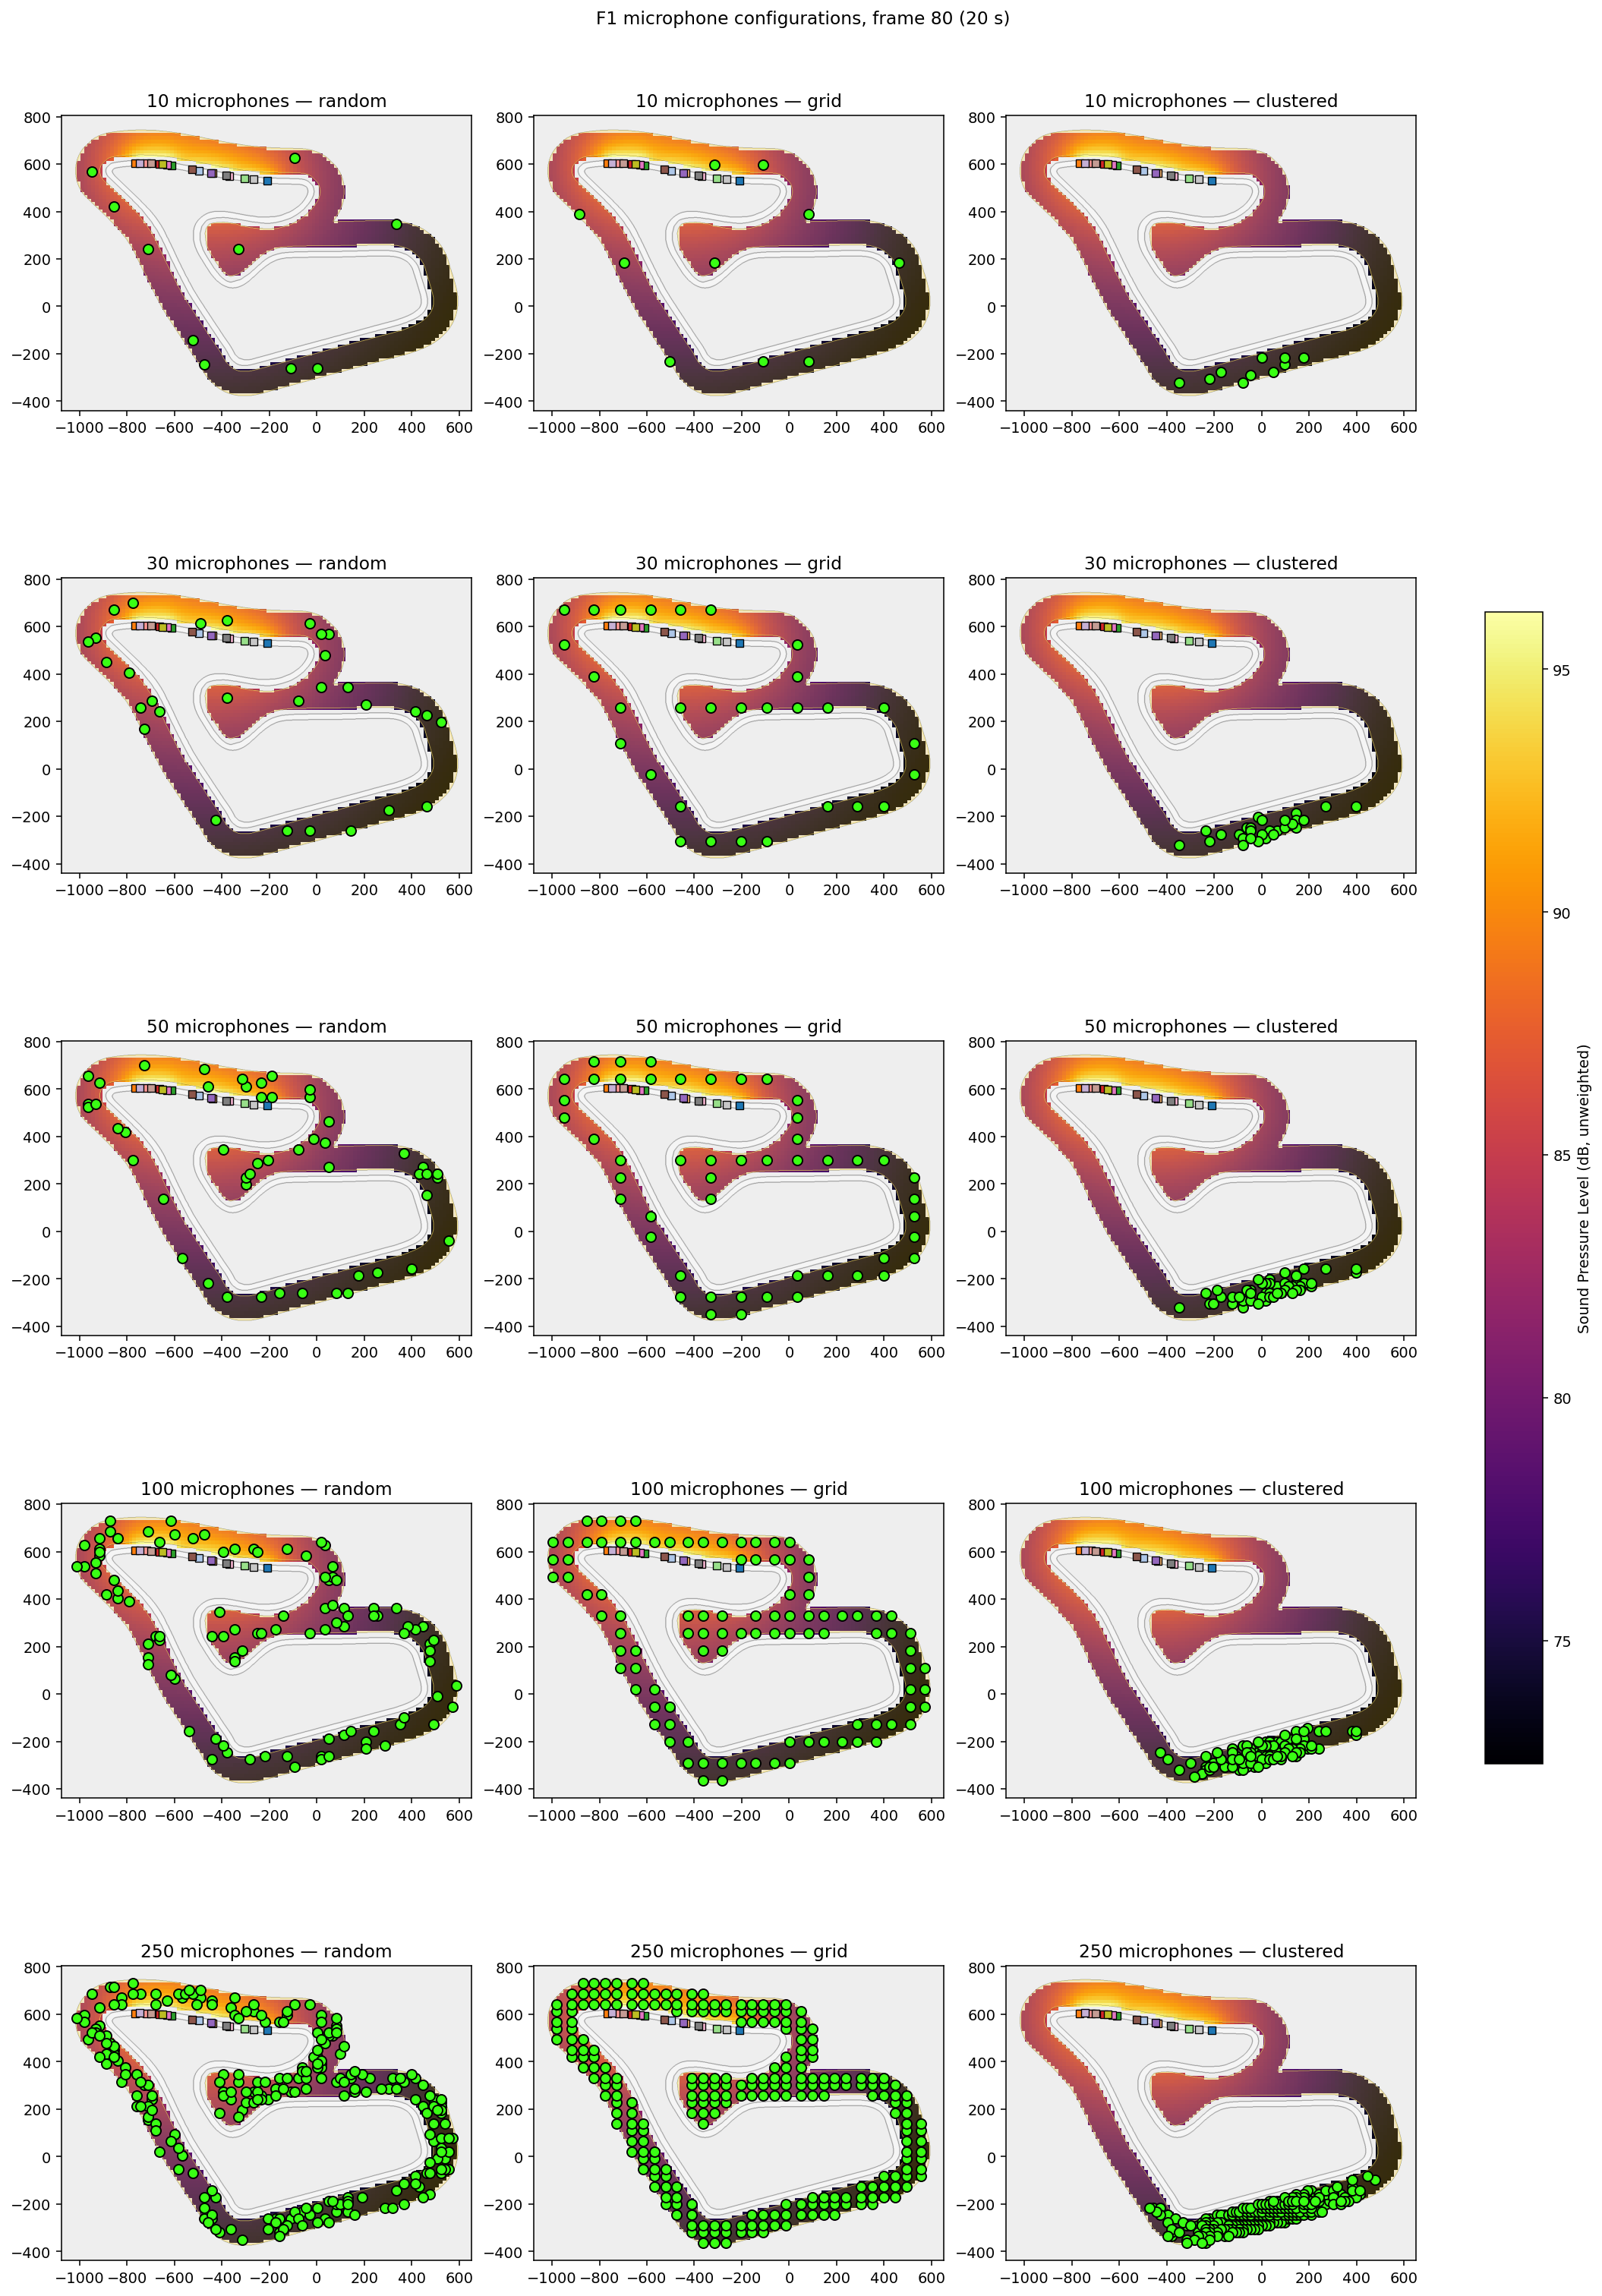

In [4]:
display(Image(filename=str(EVALUATION / 'f1_all_microphone_configurations.png')))

## 5. True field, two GP predictions, and absolute error

The example uses **100 grid microphones at frame 80 (20 s)**. The first three panels share the same sound-level colour limits. Neon-green dots mark microphones on the prediction and error panels. GP results are displayed only inside the allowed spectator mask; areas outside it have no GP prediction or score. Track, viewing-area, and car overlays provide geographic context. The final panel is absolute error in dB, available because this is a simulation; it is not GP uncertainty. Microphone cells are displayed but excluded from scores.

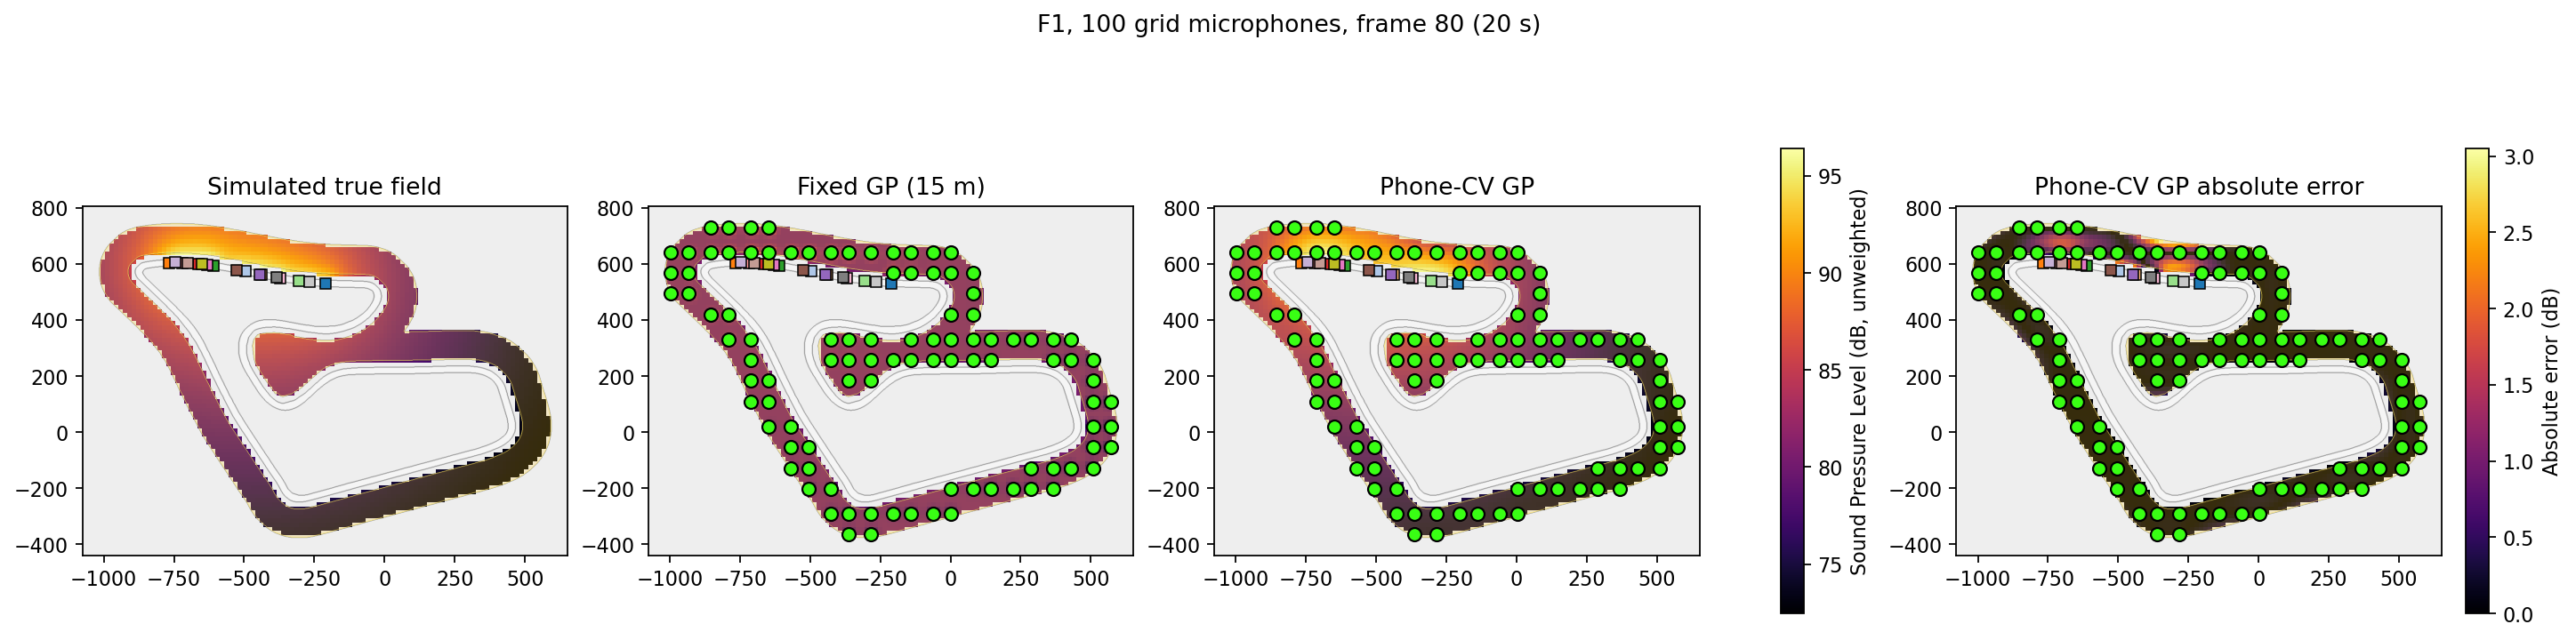

In [5]:
display(Image(filename=str(EVALUATION / 'f1_gp_baseline_vs_tuned_100_grid.png')))

## 6. Error versus microphone count

Each panel compares fixed and phone-validated GP under one sampling layout. Its RMSE covers **every unobserved audience cell and all 721 frames**. Increasing phone count need not give a perfectly monotone curve because the sampler chooses a new configuration at each count; the sets are not necessarily nested.

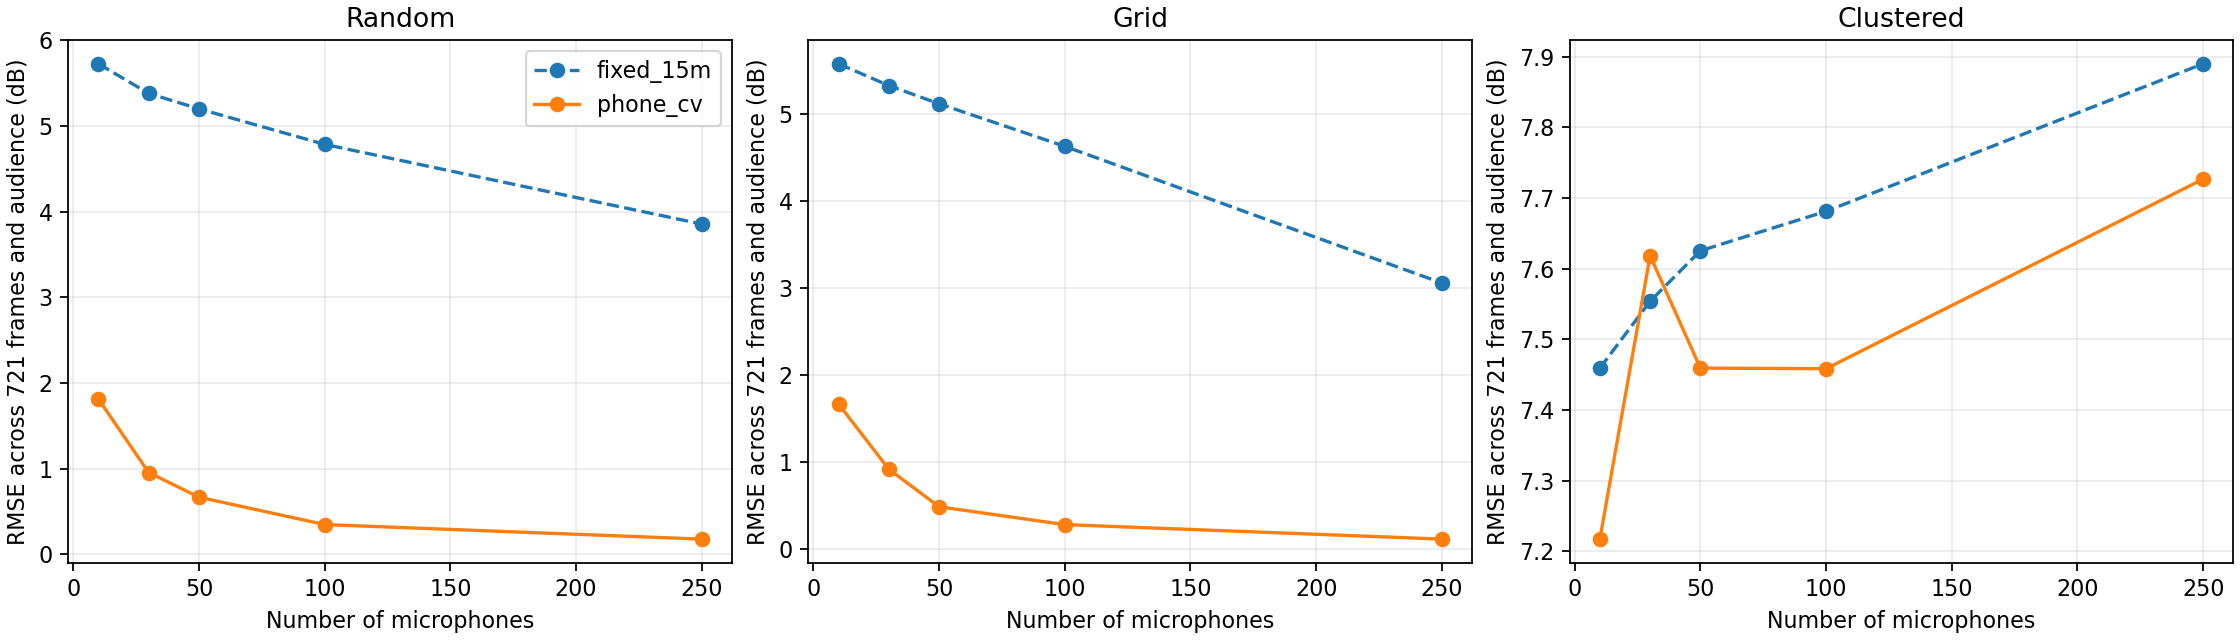

In [6]:
display(Image(filename=str(EVALUATION / 'f1_gp_baseline_vs_tuned_rmse.png')))

## 7. Error over simulated time

For the 100-grid configuration, the curves show spectator RMSE at each recorded time, excluding microphone cells. The dotted line marks the displayed frame at 20 s. These are independent spatial GP reconstructions with shared locations and length scale, not a space-time GP.

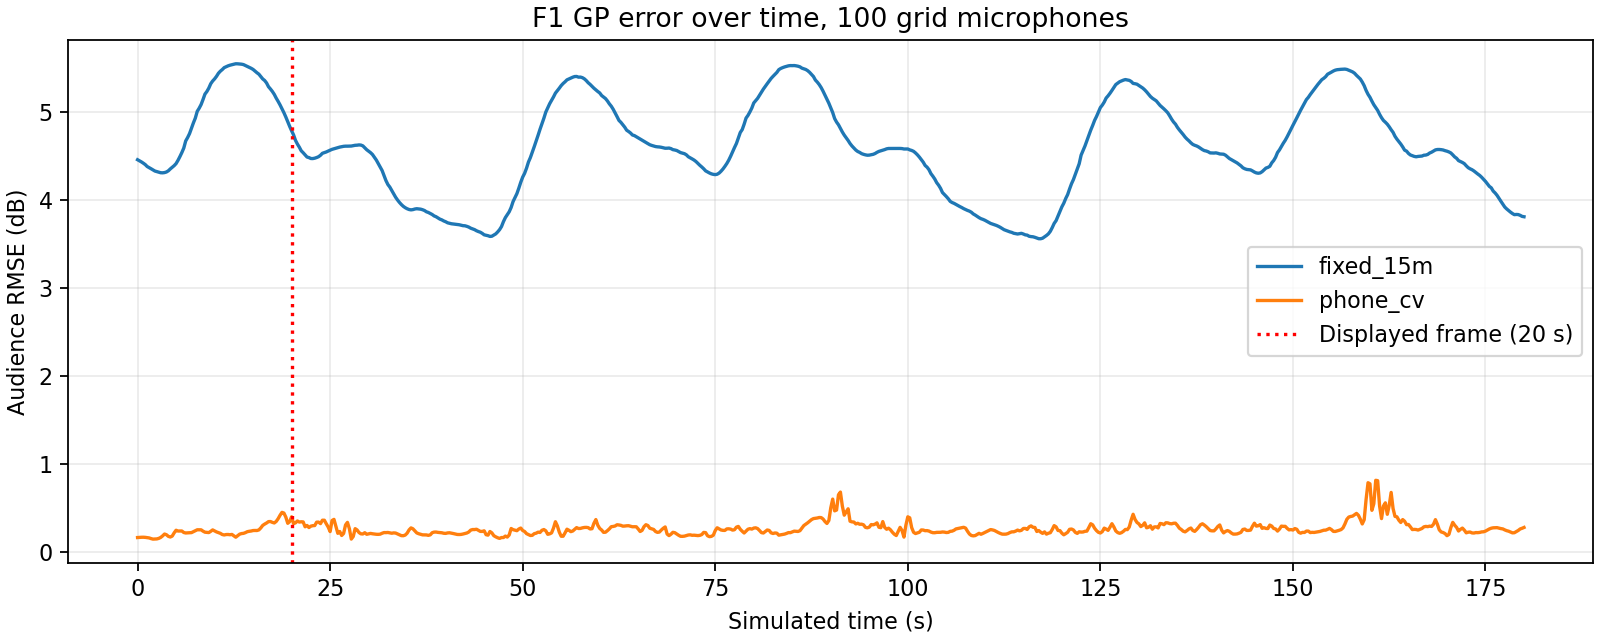

In [7]:
display(Image(filename=str(EVALUATION / 'f1_gp_rmse_over_time_100_grid.png')))

## 8. Inspect the 100-grid length-scale choice

Phone CV predicts each held-out microphone from the others, across all 721 frames. The selected value is compared with the complete-map score above; the latter is used only to assess the finished prediction.

In [8]:
cv = [r for r in read_csv(PREDICTIONS / 'phone_cv_scores.csv')
      if r['phone_count'] == '100' and r['layout'] == 'grid']
selected = next(r for r in read_csv(PREDICTIONS / 'selected_length_scales.csv')
                if r['phone_count'] == '100' and r['layout'] == 'grid')
lines = ['| Candidate length scale (m) | Held-out phone RMSE (dB) |',
         '|--:|--:|']
for row in cv:
    lines.append(f"| {float(row['length_scale_m']):g} | "
                 f"{float(row['phone_cv_RMSE_db']):.3f} |")
display(Markdown('\n'.join(lines)))
print('Selected length scale:', selected['selected_length_scale_m'], 'm')

Selected length scale: 150.0 m


| Candidate length scale (m) | Held-out phone RMSE (dB) |
|--:|--:|
| 15 | 5.743 |
| 30 | 5.166 |
| 60 | 2.127 |
| 100 | 0.776 |
| 150 | 0.502 |
| 250 | 0.511 |
| 400 | 0.674 |

## 9. Saved data and interpretation limits

- `source_files.csv`: paths and hashes for the map generator, sampler, trajectory CSV, and overlay.
- `model_inputs/`: query coordinates, mask, axes, frame times, and all 15 observation sets.
- `gp_predictions/`: all 30 predicted sequences, CV scores, selected lengths, and settings.
- `evaluation_only/`: hidden truth, evaluation masks, overall and per-frame metrics, and four figures.

The shared sampler reads ideal grid-cell sound levels. No extra phone noise, GPS error, missing readings, or device bias is injected. The source sums car energies using inverse-square spreading; results do not establish real circuit or smartphone accuracy.

In [9]:
manifest = read_csv(OUTPUT / 'run_manifest.csv')
print('Configurations:', len(manifest))
print('Frame-level metric rows:', len(read_csv(EVALUATION / 'frame_metrics.csv')))
print('Saved figures:')
for path in sorted(EVALUATION.glob('*.png')):
    print(' -', path.name)
print('To rebuild everything, set RUN_MODEL = True in section 1 and run all cells.')

Configurations: 30
Frame-level metric rows: 21630
Saved figures:
 - f1_all_microphone_configurations.png
 - f1_gp_baseline_vs_tuned_100_grid.png
 - f1_gp_baseline_vs_tuned_rmse.png
 - f1_gp_rmse_over_time_100_grid.png
To rebuild everything, set RUN_MODEL = True in section 1 and run all cells.
